We use log loss instead of MSE in logistic regression because we are predicting probabilities for classes, not continuous numbers. Log loss penalizes the model more when it gives a very low probability to the correct answer, especially when it is confident but wrong. That is why log loss is more suitable for logistic regression.

In [1]:

#import the libraries and load the data 

from sklearn.datasets import load_breast_cancer 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss

data = load_breast_cancer()

X = data.data #input features
y = data.target #predection labels 

print("Features:", X.shape)
print("Classes:", data.target_names)

Features: (569, 30)
Classes: ['malignant' 'benign']


In [2]:

#Split the data and train the model

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [3]:

# Predicted classes
y_pred = model.predict(X_test)

# Predicted probabilities
y_prob = model.predict_proba(X_test)

print("Actual classes:", y_test[:5])
print("Predicted classes:", y_pred[:5])
print("Predicted probabilities:")
print(y_prob[:5])

Actual classes: [0 1 0 1 0]
Predicted classes: [0 1 0 1 0]
Predicted probabilities:
[[9.99999941e-01 5.88824186e-08]
 [1.13351672e-05 9.99988665e-01]
 [9.93589175e-01 6.41082462e-03]
 [4.66491463e-01 5.33508537e-01]
 [9.99999999e-01 6.52500097e-10]]


In [4]:
#Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred)) #measures the proportion of correct class predictions
print("Log loss:", log_loss(y_test, y_prob))  #evaluates the quality of the predicted probabilities; lower is better

Accuracy: 0.9824561403508771
Log loss: 0.07774649384096737


In [5]:
#Understand how the class is chosen
print("Class order:", model.classes_)

for i in range(5):
    probabilities = y_prob[i]
    predicted_class = y_pred[i]

    print("Probabilities:", probabilities)
    print("Predicted class:", predicted_class)

Class order: [0 1]
Probabilities: [9.99999941e-01 5.88824186e-08]
Predicted class: 0
Probabilities: [1.13351672e-05 9.99988665e-01]
Predicted class: 1
Probabilities: [0.99358918 0.00641082]
Predicted class: 0
Probabilities: [0.46649146 0.53350854]
Predicted class: 1
Probabilities: [9.99999999e-01 6.52500097e-10]
Predicted class: 0


In [6]:
prob_class_1 = y_prob[:, 1]

custom_predictions = (prob_class_1 >= 0.8).astype(int)

print(custom_predictions[:5])

[0 1 0 0 0]


In [7]:
model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)
predictions = model.predict(X_test)

print(probabilities[:5])
print(predictions[:5])

[[9.99999941e-01 5.88824186e-08]
 [1.13351672e-05 9.99988665e-01]
 [9.93589175e-01 6.41082462e-03]
 [4.66491463e-01 5.33508537e-01]
 [9.99999999e-01 6.52500097e-10]]
[0 1 0 1 0]


In [ ]:
IMBALANCED DATA AND THE ACCURACY TRAP 

In [8]:
#import the libraries and create the dataset 
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    weights=[0.95, 0.05],
    random_state=42
)

print("Class counts:", np.bincount(y))

Class counts: [947  53]


In [10]:
#Split the data and train the model
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [11]:
#report the accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model accuracy:", accuracy)

Model accuracy: 0.952


In [12]:
#investigate whether it detects the minority class with confusion matrix 
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[233   4]
 [  8   5]]


In [13]:
#Comparing against a simple baseline
baseline_pred = np.zeros_like(y_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_cm = confusion_matrix(y_test, baseline_pred)

print("Baseline accuracy:", baseline_accuracy)
print("Baseline confusion matrix:")
print(baseline_cm)

Baseline accuracy: 0.948
Baseline confusion matrix:
[[237   0]
 [ 13   0]]


Metric	Logistic regression	  Baseline
Accuracy	       95.2%	    94.8%
Class 0 correct 	233	         237
Class 1 correct      5	          0
Class 1 missed	     8	          13

The baseline achieved 94.8% accuracy by always predicting the majority class (class 0), but it failed to detect any examples of class 1. Logistic regression achieved 95.2% accuracy and correctly detected 5 examples of class 1, although it still missed 8. This shows that accuracy alone can be misleading when the dataset is imbalanced. The confusion matrix gives us a clearer picture of how well the model predicts each class.

In [14]:
# Get TP, FP, TN, and FN from the confusion matrix
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

# Calculate precision
precision = tp / (tp + fp) if (tp + fp) != 0 else 0

# Calculate recall
recall = tp / (tp + fn) if (tp + fn) != 0 else 0

# Calculate F1-score
f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) != 0 else 0
)

print("TP:", tp)
print("FP:", fp)
print("TN:", tn)
print("FN:", fn)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

TP: 5
FP: 4
TN: 233
FN: 8
Precision: 0.5556
Recall: 0.3846
F1-score: 0.4545


Precision = 55.56%: About 56% of the examples predicted as class 1 were actually class 1.

Recall = 38.46%: The model detected about 38% of all actual class 1 examples.

F1-score = 45.45%: The combined score reflects the balance between precision and recall.

In [15]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.98      0.97       237
           1       0.56      0.38      0.45        13

    accuracy                           0.95       250
   macro avg       0.76      0.68      0.71       250
weighted avg       0.95      0.95      0.95       250



Precision tells us how many predicted positive cases are actually positive, while recall tells us how many actual positive cases the model successfully finds. F1-score combines precision and recall into one metric. I would favor precision in spam detection to avoid marking important emails as spam. I would favor recall in disease screening because missing a person who has a disease could be dangerous.

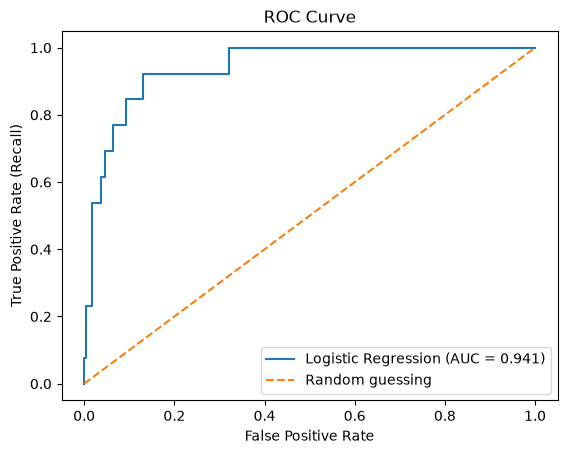

ROC AUC: 0.9409


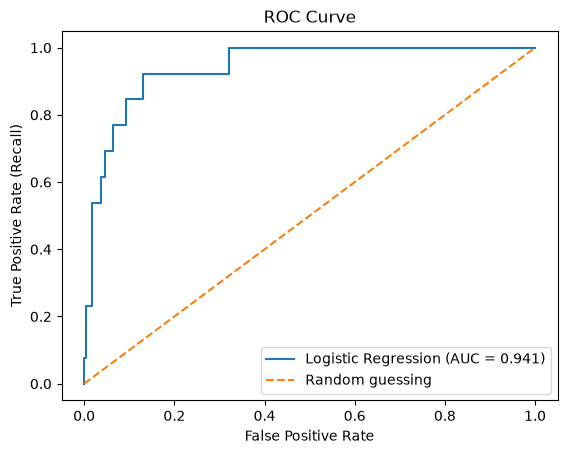

ROC AUC: 0.9409


In [17]:
#Plotting the ROC curve

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Get probabilities for class 1
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

# Plot the ROC curve
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random guessing")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend()
plt.show()

print("ROC AUC:", round(auc_score, 4))
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Get probabilities for class 1
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

# Plot the ROC curve
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random guessing")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend()
plt.show()

print("ROC AUC:", round(auc_score, 4))

In [18]:

#Compare threshold 0.5 with threshold 0.3

from sklearn.metrics import confusion_matrix, precision_score, recall_score

# Predictions using the default threshold of 0.5
pred_05 = (y_prob >= 0.5).astype(int)

# Predictions using the new threshold of 0.3
pred_03 = (y_prob >= 0.3).astype(int)

# Compare both thresholds
for threshold, predictions in [(0.5, pred_05), (0.3, pred_03)]:
    cm = confusion_matrix(y_test, predictions)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )
    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    print(f"\nThreshold: {threshold}")
    print("Confusion matrix:")
    print(cm)
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))


Threshold: 0.5
Confusion matrix:
[[233   4]
 [  8   5]]
Precision: 0.5556
Recall: 0.3846

Threshold: 0.3
Confusion matrix:
[[230   7]
 [  6   7]]
Precision: 0.5
Recall: 0.5385


ROC AUC measures how well a model can distinguish between positive and negative classes. An AUC of 0.5 means the model has random-ranking performance, while an AUC of 1.0 means perfect separation. A threshold of 0.5 is not always the best choice because different situations have different priorities. For medical screening, I would try a lower threshold, such as 0.3, to detect more possible cases. I would then compare the confusion matrix, precision, and recall at both thresholds to see how the results change.

At a threshold of 0.5, the model achieved 55.56% precision and 38.46% recall. When I lowered the threshold to 0.3, precision decreased to 50%, but recall increased to 53.85%. The model detected more positive cases and missed fewer of them, but it also produced more false positives. I would choose the lower threshold for an initial medical screening scenario because detecting more possible cases is important, even if some healthy people need additional testing.